# Scikit Learn

### Plot Datapoints

In [1]:
import matplotlib.pyplot as plt
# Create two list
x=[ i for i in range(10)]
y= [2*i for i in range(10)]
x,y

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], [0, 2, 4, 6, 8, 10, 12, 14, 16, 18])

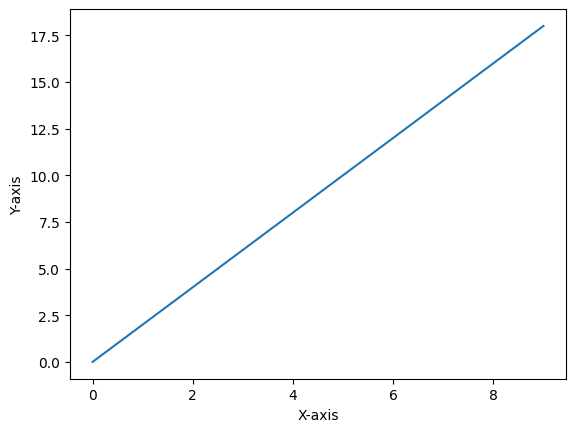

In [2]:
# plot a line
plt.plot(x,y)
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.show()

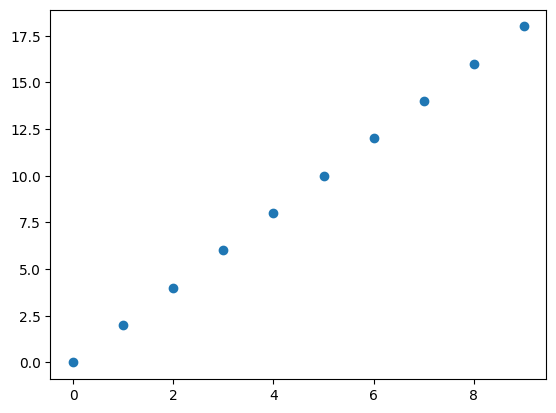

In [3]:
# plot all the datapoints
plt.scatter(x,y)
plt.show()

### Features and Labels
- Features: Input information used by the model to make a prediction.
- Labels: Correct output values the model learns to predict.
- Number of features = input dimensions, when each feature is a single value.

### Train Test split

In [4]:
from sklearn import datasets
import numpy as np

# load iris data
iris=datasets.load_iris()

# split into features and label
X=iris.data
y=iris.target
print(X,y)
print(f"\nFeature shape: {X.shape}\nLable Shape: {y.shape}  ")

# split into train and test set
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)
print(f"\nX_train: {X_train.shape}\nX_test : {X_test.shape}\ny_train: {y_train.shape}\ny_test: {y_test.shape} ")

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

### KNN (K-Nearest Neighbors)
- Used for classification and regression.
- K is the number of nearest training examples considered for a new sample.
- A small K can be sensitive to noise; a large K can smooth over useful patterns. Choose K based on model performance.
- An odd K can help avoid ties in binary classification.
- Neighbors can have equal weights (uniform) or closer neighbors can have more influence (distance-based).

In [5]:
import numpy as np
import pandas as pd
from sklearn import neighbors,metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# read the data 
data=pd.read_csv('car+evaluation/car.data')
# get top 5 rows of the dataset
print(f"first 5 rows:\n{data.head()} ")

# split into features and label
# taking only 3 features 
X=data[['buying','maint','safety']].values
y=data[['class']]

# Converting categorical features into numbers
Le=LabelEncoder()
for i in range(len(X[0])):
    X[:,i]=Le.fit_transform(X[:,i])
print(f"\nConverted Data into numbers:\n{X} ")

# Convert label into numbers
label_maping={
    "unacc":0,
    "acc":1, 
    "good":2, 
    "vgood":3
}
y['class']=y['class'].map(label_maping)
y = y["class"].to_numpy()
print(f"\nLables converted into numbers:\n{y} ")

# Defining the model
knn=neighbors.KNeighborsClassifier(n_neighbors=25,weights='uniform')

# split into test and train
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)

# Train the model
knn.fit(X_train,y_train)

# Make prediction
prediction=knn.predict(X_test)

# find accuracy
accuracy=metrics.accuracy_score(y_test,prediction)

# Print prediction and accuracy
print(f"\nPrediction:\n{prediction}\nAccuracy: {accuracy} ")

# print actual value and predicted value
print(f"\nActual Value:{y[45]}\nPredicted value: {knn.predict(X)[45]} ")


first 5 rows:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc 

Converted Data into numbers:
[[3 3 1]
 [3 3 2]
 [3 3 0]
 ...
 [1 1 1]
 [1 1 2]
 [1 1 0]] 

Lables converted into numbers:
[0 0 0 ... 0 2 3] 

Prediction:
[1 0 0 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 3 3 0 0 0 0 0 1 0 0 0 1 0 0
 1 0 0 0 0 1 0 1 0 0 1 1 0 0 1 0 0 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 1 0 0
 0 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0
 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 3 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 1 0 0 0 0 0 1
 1 1 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0

### SVM (Support Vector Machine)
- Can be used for classification and regression.
- Choose a kernel based on the data and task. A linear kernel gives a straight boundary; polynomial and RBF kernels can give curved boundaries.
- The kernel measures similarities between data points; it doesn’t physically move them.
- SVM uses the support vectors—the points closest to the boundary—to find a boundary with the widest margin between classes.

In [10]:
from sklearn import datasets
import numpy as np
from sklearn import svm
from sklearn.metrics import accuracy_score
# load iris data
iris=datasets.load_iris()

# split into features and label
X=iris.data
y=iris.target
print(X,y)
print(f"\nFeature shape: {X.shape}\nLable Shape: {y.shape}  ")

claases=['Iris Setosa', 'Iris Versicolour', 'Iris Virginica']

# split into train and test set
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)
print(f"\nX_train: {X_train.shape}\nX_test : {X_test.shape}\ny_train: {y_train.shape}\ny_test: {y_test.shape} ")

# Define model
model=svm.SVC()

# Train model
model.fit(X_train,y_train)

# make prediction
prediction=model.predict(X_test)

# find aaccuracy
accuracy=accuracy_score(y_test,prediction)

# print prediction and accuracy
print(f"Prediction:\n{prediction}\nActual value:\n{y_test}\nAccuracy: {accuracy} ")

for i in range(len(prediction)):
    print(claases[prediction[i]])

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.